# Preparar dataset externo — Road Damage (Zenodo)

Este notebook baixa o dataset independente do SVRDD, filtra `pothole` e `manhole`, converte as classes para o padrão do UrbanSense e gera um ZIP pronto para avaliação YOLO.

**Fonte:** https://zenodo.org/records/18528034  
**Licença:** CC BY 4.0  
**Atenção:** o dataset original tem imagens de 640×360. Para comparar com o teste interno, mantenha a inferência em `imgsz=1088` (o Ultralytics ajusta 1080 para 1088).


In [1]:
from pathlib import Path
import zipfile, requests, shutil, os, re, json
from collections import Counter
from PIL import Image

WORK = Path.cwd() / "road_damage_external"
SOURCE_ZIP = WORK / "data.zip"
EXTRACT_DIR = WORK / "original"
OUTPUT_DIR = WORK / "road_damage_yolo"
OUTPUT_ZIP = Path.cwd() / "road_damage_external_yolo.zip"

WORK.mkdir(parents=True, exist_ok=True)
URL = "https://zenodo.org/records/18528034/files/data.zip?download=1"


In [2]:
# Baixa o arquivo original (194,2 MB). Se já existir, reutiliza.
if not SOURCE_ZIP.exists() or SOURCE_ZIP.stat().st_size < 1_000_000:
    with requests.get(URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        downloaded = 0
        with open(SOURCE_ZIP, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024*1024):
                if chunk:
                    f.write(chunk)
                    downloaded += len(chunk)
                    if total:
                        print(f"Baixado: {downloaded/total:.1%}", end="\r")
    print("\nDownload concluído:", SOURCE_ZIP, f"({SOURCE_ZIP.stat().st_size/1024**2:.1f} MB)")
else:
    print("Arquivo já existe:", SOURCE_ZIP, f"({SOURCE_ZIP.stat().st_size/1024**2:.1f} MB)")


Baixado: 100.0%
Download concluído: /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/src/road_damage_external/data.zip (185.2 MB)


In [3]:
# Confere e extrai o arquivo original.
with zipfile.ZipFile(SOURCE_ZIP) as z:
    bad = z.testzip()
    if bad:
        raise RuntimeError(f"ZIP corrompido no membro: {bad}")
    print("Total de arquivos no ZIP:", len(z.namelist()))
    print("\nAmostra da estrutura:")
    for name in z.namelist()[:35]:
        print(name)
    z.extractall(EXTRACT_DIR)

print("\nExtração concluída em:", EXTRACT_DIR)


Total de arquivos no ZIP: 6035

Amostra da estrutura:
data/
data/images/
data/images/vlcsnap_2025-03-16-15h31m42s236.jpg
data/images/vlcsnap-00162.jpg
data/images/vlcsnap-2025-02-18-23h28m55s133.jpg
data/images/vlcsnap_2025-03-16-15h18m40s531.jpg
data/images/vlcsnap_2025-03-16-15h17m57s358.jpg
data/images/vlcsnap-2025-02-18-17h03m54s730.jpg
data/images/20250223_144944.jpg
data/images/vlcsnap-2025-02-19-14h25m44s752.jpg
data/images/vlcsnap-2025-02-26-20h36m21s506.jpg
data/images/vlcsnap-2025-02-19-15h05m55s804.jpg
data/images/vlcsnap-2025-02-19-15h03m06s067.jpg
data/images/vlcsnap-2025-02-18-18h48m22s424.jpg
data/images/vlcsnap-2025-02-19-14h52m42s234.jpg
data/images/vlcsnap-00137.jpg
data/images/vlcsnap_2025-03-16-15h26m47s658.jpg
data/images/vlcsnap-2025-02-18-18h46m34s348.jpg
data/images/vlcsnap-00110.jpg
data/images/vlcsnap_2025-03-16-15h21m03s270.jpg
data/images/vlcsnap-2025-02-19-14h17m12s979.jpg
data/images/vlcsnap-2025-02-19-14h24m33s862.jpg
data/images/vlcsnap-2025-02-19-13h52m

In [4]:
# Localiza diretórios de imagens e labels YOLO automaticamente.
image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
all_files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file()]
image_files = [p for p in all_files if p.suffix.lower() in image_exts]
label_files = [p for p in all_files if p.suffix.lower() == ".txt" and "label" in str(p.parent).lower()]

print("Imagens encontradas:", len(image_files))
print("TXT em diretórios com 'label':", len(label_files))
print("Pastas de labels:", sorted({str(p.parent.relative_to(EXTRACT_DIR)) for p in label_files})[:20])

if not image_files or not label_files:
    raise RuntimeError(
        "Não consegui localizar imagens e labels automaticamente. "
        "Confira a estrutura impressa na célula anterior e ajuste a localização."
    )

# Índice de labels pelo nome-base; se houver nomes repetidos, prioriza a pasta labels-YOLO.
label_by_stem = {}
for p in label_files:
    old = label_by_stem.get(p.stem)
    score = 2 if "labels-yolo" in str(p.parent).lower() else 1
    old_score = (2 if old and "labels-yolo" in str(old.parent).lower() else 1) if old else -1
    if score > old_score:
        label_by_stem[p.stem] = p

image_by_stem = {}
for p in image_files:
    image_by_stem.setdefault(p.stem, p)

print("Pares possíveis:", len(set(image_by_stem) & set(label_by_stem)))


Imagens encontradas: 2009
TXT em diretórios com 'label': 4018
Pastas de labels: ['data/labels', 'data/labels-YOLO']
Pares possíveis: 2009


In [5]:
# Converte: origem 0=pothole -> destino 0; origem 2=manhole -> destino 1.
# Origem 1=crack é descartada. Imagens contendo somente crack permanecem como negativas.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
(OUTPUT_DIR / "images").mkdir(parents=True)
(OUTPUT_DIR / "labels").mkdir(parents=True)

counts = Counter()
images_with_target = 0
negatives = 0
missing_labels = []
used_names = set()

for stem, img_path in image_by_stem.items():
    label_path = label_by_stem.get(stem)
    if label_path is None:
        missing_labels.append(img_path.name)
        continue

    kept = []
    for line in label_path.read_text(encoding="utf-8", errors="ignore").splitlines():
        parts = line.strip().split()
        if len(parts) < 5:
            continue
        try:
            cls = int(float(parts[0]))
            vals = [float(x) for x in parts[1:5]]
        except ValueError:
            continue

        if cls == 0:
            new_cls = 0
        elif cls == 2:
            new_cls = 1
        else:
            continue

        # Mantém somente caixas YOLO válidas e normalizadas.
        if not all(0 <= x <= 1 for x in vals):
            continue
        if vals[2] <= 0 or vals[3] <= 0:
            continue
        kept.append(f"{new_cls} " + " ".join(f"{x:.8f}" for x in vals))
        counts[new_cls] += 1

    # Nome único e estável para evitar colisões de stems.
    safe_name = re.sub(r"[^A-Za-z0-9_.-]+", "_", img_path.name)
    if safe_name in used_names:
        safe_name = f"{img_path.parent.name}_{safe_name}"
    used_names.add(safe_name)

    shutil.copy2(img_path, OUTPUT_DIR / "images" / safe_name)
    (OUTPUT_DIR / "labels" / f"{Path(safe_name).stem}.txt").write_text(
        "\n".join(kept), encoding="utf-8"
    )
    if kept:
        images_with_target += 1
    else:
        negatives += 1

print("Imagens exportadas:", len(list((OUTPUT_DIR / "images").iterdir())))
print("Imagens com objetos-alvo:", images_with_target)
print("Imagens negativas:", negatives)
print("Caixas por classe:", dict(counts))
print("Imagens sem label correspondente:", len(missing_labels))

if sum(counts.values()) == 0:
    raise RuntimeError("Nenhuma anotação pothole/manhole foi convertida. Revise o mapeamento.")


Imagens exportadas: 2009
Imagens com objetos-alvo: 1318
Imagens negativas: 691
Caixas por classe: {0: 1261, 1: 957}
Imagens sem label correspondente: 0


In [6]:
# Gera data.yaml compatível com Ultralytics.
yaml_text = f'''path: {OUTPUT_DIR.resolve().as_posix()}
train: images
val: images
test: images
names:
  0: pothole
  1: manhole_cover
'''
(OUTPUT_DIR / "data.yaml").write_text(yaml_text, encoding="utf-8")
print(yaml_text)


path: /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/src/road_damage_external/road_damage_yolo
train: images
val: images
test: images
names:
  0: pothole
  1: manhole_cover



In [7]:
# Verificação de integridade: imagens legíveis, labels correspondentes e contagem.
imgs = sorted((OUTPUT_DIR / "images").iterdir())
assert imgs, "Nenhuma imagem exportada."
corrupt = []
for p in imgs:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corrupt.append(p.name)

label_names = {p.stem for p in (OUTPUT_DIR / "labels").glob("*.txt")}
image_stems = {p.stem for p in imgs}
print("Imagens:", len(imgs))
print("Labels:", len(label_names))
print("Imagens sem TXT:", len(image_stems - label_names))
print("Imagens corrompidas:", len(corrupt))
assert not corrupt, f"Imagens corrompidas: {corrupt[:10]}"
assert image_stems == label_names, "Há divergência entre imagens e labels."


Imagens: 2009
Labels: 2009
Imagens sem TXT: 0
Imagens corrompidas: 0


In [8]:
# Empacota o dataset filtrado para facilitar transferência/backup.
if OUTPUT_ZIP.exists():
    OUTPUT_ZIP.unlink()

with zipfile.ZipFile(OUTPUT_ZIP, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=3) as z:
    for p in OUTPUT_DIR.rglob("*"):
        if p.is_file():
            z.write(p, p.relative_to(OUTPUT_DIR.parent))

print("ZIP pronto:", OUTPUT_ZIP.resolve())
print(f"Tamanho: {OUTPUT_ZIP.stat().st_size/1024**2:.1f} MB")


ZIP pronto: /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/src/road_damage_external_yolo.zip
Tamanho: 184.4 MB


## Avaliar o modelo


In [2]:
from pathlib import Path
from ultralytics import YOLO

PROJECT_DIR = Path(
    "/run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense"
)

model_name = "yolo11s"

WEIGHTS = (
    PROJECT_DIR
    / "runs"
    / "potholes-yolo11s-v1"
    / "weights"
    / "best.pt"
)

DATA_YAML = (
    PROJECT_DIR
    / "data"
    / "road_damage_external"
    / "road_damage_yolo"
    / "data.yaml"
)

if not WEIGHTS.is_file():
    raise FileNotFoundError(f"Pesos não encontrados: {WEIGHTS}")

if not DATA_YAML.is_file():
    raise FileNotFoundError(f"Dataset não encontrado: {DATA_YAML}")

model = YOLO(str(WEIGHTS))

metrics = model.val(
    data=str(DATA_YAML),
    split="test",
    imgsz=1088,
    batch=1,
    device=0,
    workers=0,
    plots=True,
)

Ultralytics 8.4.220 🚀 Python-3.14.4 torch-2.15.0+rocm10.2.0 CUDA:0 (AMD Radeon RX 7600, 8176MiB)
YOLO11s summary (fused): 100 layers, 9,413,574 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 518.5±55.2 MB/s, size: 96.9 KB)
val: Scanning /run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense/data/road_damage_external/road_damage_yolo/labels.cache... 2009 images, 691 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2009/2009 601.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2009/2009 55.8it/s 36.0s0.0ss
                   all       2009       2218      0.162      0.151     0.0647      0.022
               pothole        795       1261       0.16      0.223     0.0873     0.0283
         manhole_cover        759        957      0.164     0.0784     0.0422     0.0157
Speed: 0.3ms preprocess, 12.4ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /run/media

Imagens encontradas: 2009
Imagens com objetos: 1318
Backgrounds: 691


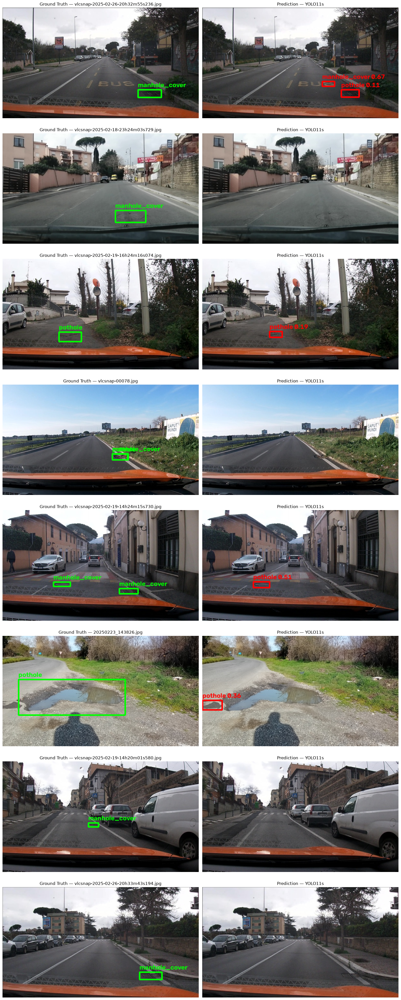

In [5]:
from pathlib import Path
import random
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = Path(
    "/run/media/pedro-martins/Windows/Workspace/Study/UPE/urbansense"
)

DATASET_DIR = PROJECT_DIR / "data/road_damage_external/road_damage_yolo"

IMAGE_DIR = DATASET_DIR / "images"
LABEL_DIR = DATASET_DIR / "labels"

WEIGHTS = PROJECT_DIR / "runs/potholes-yolo11s-v1/weights/best.pt"

NUM_IMAGES = 8
CONFIDENCE = 0.10
IMAGE_SIZE = 1088
SEED = 42

CLASS_NAMES = {
    0: "pothole",
    1: "manhole_cover",
}

model = YOLO(str(WEIGHTS))

# Localiza todas as imagens
image_files = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file()
    and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
]

if not image_files:
    raise FileNotFoundError(f"Nenhuma imagem encontrada em {IMAGE_DIR}")

print(f"Imagens encontradas: {len(image_files)}")

# Localiza as anotações correspondentes
def get_label_path(image_path):
    relative_path = image_path.relative_to(IMAGE_DIR)
    return LABEL_DIR / relative_path.with_suffix(".txt")


# Seleciona imagens com e sem objetos anotados
random.seed(SEED)

images_with_labels = []
background_images = []

for image_path in image_files:
    label_path = get_label_path(image_path)

    if label_path.exists() and label_path.stat().st_size > 0:
        images_with_labels.append(image_path)
    else:
        background_images.append(image_path)

selected = random.sample(
    images_with_labels,
    min(NUM_IMAGES, len(images_with_labels))
)

print(f"Imagens com objetos: {len(images_with_labels)}")
print(f"Backgrounds: {len(background_images)}")

# Inferência
predictions = model.predict(
    source=[str(p) for p in selected],
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE,
    iou=0.7,
    device=0,
    verbose=False,
)

# Ground Truth
def draw_ground_truth(image, image_path):
    output = image.copy()
    label_path = get_label_path(image_path)

    if not label_path.exists():
        return output

    height, width = output.shape[:2]

    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue

        class_id, cx, cy, bw, bh = map(float, line.split())

        x1 = int((cx - bw / 2) * width)
        y1 = int((cy - bh / 2) * height)
        x2 = int((cx + bw / 2) * width)
        y2 = int((cy + bh / 2) * height)

        cv2.rectangle(output, (x1, y1), (x2, y2), (0, 255, 0), 3)

        label = CLASS_NAMES.get(int(class_id), str(int(class_id)))

        cv2.putText(
            output,
            label,
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2,
        )

    return output


# Predictions
def draw_predictions(image, result):
    output = image.copy()

    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        cv2.rectangle(output, (x1, y1), (x2, y2), (255, 0, 0), 3)

        label = f"{CLASS_NAMES.get(class_id, class_id)} {confidence:.2f}"

        cv2.putText(
            output,
            label,
            (x1, max(20, y1 - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 0, 0),
            2,
        )

    return output


# Exibição
fig, axes = plt.subplots(
    len(selected),
    2,
    figsize=(16, 5 * len(selected))
)

if len(selected) == 1:
    axes = [axes]

for idx, (image_path, result) in enumerate(zip(selected, predictions)):
    original = cv2.cvtColor(
        cv2.imread(str(image_path)),
        cv2.COLOR_BGR2RGB
    )

    gt = draw_ground_truth(original, image_path)
    pred = draw_predictions(original, result)

    axes[idx][0].imshow(gt)
    axes[idx][0].set_title(f"Ground Truth — {image_path.name}")
    axes[idx][0].axis("off")

    axes[idx][1].imshow(pred)
    axes[idx][1].set_title("Prediction — YOLO11s")
    axes[idx][1].axis("off")

plt.tight_layout()
plt.show()